# eFigures 1–4. Sample distributions

- **eFigure 1.** Anthropometric measures by sex
- **eFigure 2.** Anthropometric measures by ABCD visit and sex
- **eFigure 3.** Age
- **eFigure 4.** Puberty (PDS)


In [1]:
import os
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

SEX_COL = "ab_g_stc__cohort_sex"
#SEX_PALETTE = {"F": "#FC278E", "M": "#27D5FC"}
SEX_PALETTE = {"F": "#D10467", "M": "#0011A3"}
SEX_LABELS = {"F": "Females", "M": "Males"}

SESSION_ID_ORDER = ["ses-00A", "ses-02A", "ses-04A", "ses-06A"]
SESSION_LABELS = {
    "ses-00A": "Baseline",
    "ses-02A": "Year 2",
    "ses-04A": "Year 4",
    "ses-06A": "Year 6",
}

# Histogram overlay styling — flip these to revert to the plainer look
HIST_BAR_EDGE = False          # False: no black bin outlines
HIST_BAR_EDGE_COLOR = "black"
HIST_BAR_EDGE_WIDTH = 0.6
HIST_BAR_ALPHA = 0.5
HIST_LEGEND_SOLID = False      # False: default semi-transparent legend swatches

ceph = Path(os.environ.get("BMI_IMAGING_CEPH_ROOT", "/space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis"))
SHARED_DATAFILES = Path(os.environ.get("BMI_IMAGING_SHARED_DATAFILES_DIR", ceph / "shared" / "datafiles"))
if not SHARED_DATAFILES.is_absolute():
    SHARED_DATAFILES = ceph / SHARED_DATAFILES

default_datafile = SHARED_DATAFILES / "datafile6.0_before_bfs_anthroqc_bmip_agediscrepancy_dmri_incl.txt"
DATAFILE = Path(os.environ.get("BMI_EXPLORE_DATAFILE", default_datafile))

SAVE_PLOTS = os.environ.get("BMI_SAVE_PLOTS", "1").strip().lower() in ("1", "true", "yes", "on")
EXPORT_DIR = Path(os.environ.get("BMI_DIST_EXPORT_DIR", str(ceph / "shared" / "sample_distribution_figures"))).resolve()
EXPORT_DPI = int(os.environ.get("BMI_DIST_EXPORT_DPI", "600"))

PHENO_SPECS = {
    "bmip": {
        "column": "bmip",
        "short": "bmip",
        "label": "BMI percentile",
        "xlim": (0, 100),
        "bin_width": 5,
        "bin_widths_table": (5, 10),
    },
    # "bmiz": {
    #     "column": "bmiz",
    #     "short": "bmiz",
    #     "label": "BMI z-score (extended CDC)",
    #     "xlim": (-3, 6),
    #     "bin_width": 0.5,
    #     "bin_widths_table": (0.5, 1),
    # },
    "perc_median": {
        "column": "perc_median",
        "short": "perc_median",
        "label": "Percent from median",
        "xlim": (-30, 140),
        "bin_width": 10,
        "bin_widths_table": (10, 20),
    },
    "anthro_bmi_corr": {
        "column": "anthro_bmi_corr",
        "short": "anthro_bmi",
        "label": "BMI (kg/m²)",
        "xlim": None,
        "bin_width": 2,
        "bin_widths_table": (2, 4),
    },
}


def save_fig(stem: str):
    if not SAVE_PLOTS:
        print("SAVE_PLOTS is off; not writing", stem)
        return None
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    safe = re.sub(r"[^A-Za-z0-9._-]+", "_", str(stem)).strip("_")
    out = EXPORT_DIR / f"{safe}.png"
    plt.savefig(out, dpi=EXPORT_DPI, bbox_inches="tight")
    print("Saved", out)
    return out


def load_imaging_sample(datafile=None):
    datafile = Path(datafile or DATAFILE)
    need = [
        "participant_id", "session_id", SEX_COL,
        "bmip", "bmiz", "perc_median", "anthro_bmi_corr",
        "ab_g_dyn__visit_age", "pds_categ_y_p_all",
    ]
    header = pd.read_csv(datafile, sep="\t", nrows=0).columns
    cols = [c for c in need if c in header]
    missing = [c for c in need if c not in header]
    if missing:
        raise ValueError(f"Missing columns {missing} in {datafile}")
    df = pd.read_csv(datafile, sep="\t", usecols=cols, low_memory=False)
    df = df[df[SEX_COL].isin(["F", "M"])].copy()
    for col in ["bmip", "perc_median", "anthro_bmi_corr", "ab_g_dyn__visit_age", "pds_categ_y_p_all"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df


def pheno_series(df, spec):
    col = spec["column"]
    s = df.dropna(subset=[col, SEX_COL]).copy()
    if spec["xlim"] is not None:
        lo, hi = spec["xlim"]
        s = s[(s[col] >= lo) & (s[col] <= hi)]
    return s


def make_bins(spec, values):
    if spec["xlim"] is not None:
        lo, hi = spec["xlim"]
    else:
        lo = float(np.nanpercentile(values, 1))
        hi = float(np.nanpercentile(values, 99))
    width = spec["bin_width"]
    start = np.floor(lo / width) * width
    end = np.ceil(hi / width) * width
    return np.arange(start, end + width, width)


def label_sessions(dat, id_col="session_id", label_col="session_label"):
    out = dat.copy()
    out[id_col] = out[id_col].astype(str)
    out[label_col] = out[id_col].map(SESSION_LABELS).fillna(out[id_col])
    return out


def session_label_order(dat, id_col="session_id"):
    ids = set(dat[id_col].astype(str))
    ordered = [SESSION_LABELS[s] for s in SESSION_ID_ORDER if s in ids]
    extras = sorted(ids - set(SESSION_ID_ORDER))
    ordered.extend(SESSION_LABELS.get(s, s) for s in extras)
    return ordered


def label_sex(dat, col=SEX_COL, label_col="sex_label"):
    out = dat.copy()
    out[label_col] = out[col].map(SEX_LABELS)
    return out


def style_sex_legend(legend, title="Sex"):
    if legend is not None:
        legend.set_title(title)


def print_sample_counts(df, spec):
    col = spec["column"]
    sub = pheno_series(df, spec)
    print(f"\n=== {spec['short']} ({col}) ===")
    for sex in ["F", "M"]:
        sex_df = sub[sub[SEX_COL] == sex]
        print(
            f"  {SEX_LABELS[sex]}: n_obs={len(sex_df):,}, n_subjects={sex_df['participant_id'].nunique():,}"
        )
    print(f"  Total observations: {len(sub):,}")



COVAR_SPECS = {
    "age": {
        "column": "ab_g_dyn__visit_age",
        "short": "age",
        "label": "Visit age (years)",
        "xlim": (8, 18),
        "bin_width": 0.5,
        "bin_widths_table": (0.5, 1),
    },
    "pds": {
        "column": "pds_categ_y_p_all",
        "short": "pds",
        "label": "Pubertal development stage",
        "xlim": (1, 5),
        "bin_width": 0.5,
        "bin_widths_table": (0.5, 1),
    },
}

print("datafile:", DATAFILE)
print("SAVE_PLOTS:", SAVE_PLOTS, "| EXPORT_DIR:", EXPORT_DIR)
df = load_imaging_sample()
print(f"Loaded {len(df):,} rows | subjects: {df['participant_id'].nunique():,}")
for key in PHENO_SPECS:
    print_sample_counts(df, PHENO_SPECS[key])
for key in COVAR_SPECS:
    print_sample_counts(df, COVAR_SPECS[key])


datafile: /space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis/shared/datafiles/datafile6.0_before_bfs_anthroqc_bmip_agediscrepancy_dmri_incl.txt
SAVE_PLOTS: True | EXPORT_DIR: /space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis/shared/sample_distribution_figures
Loaded 22,049 rows | subjects: 10,479

=== bmip (bmip) ===
  Females: n_obs=10,534, n_subjects=5,078
  Males: n_obs=11,515, n_subjects=5,401
  Total observations: 22,049

=== perc_median (perc_median) ===
  Females: n_obs=10,534, n_subjects=5,078
  Males: n_obs=11,515, n_subjects=5,401
  Total observations: 22,049

=== anthro_bmi (anthro_bmi_corr) ===
  Females: n_obs=10,534, n_subjects=5,078
  Males: n_obs=11,515, n_subjects=5,401
  Total observations: 22,049

=== age (ab_g_dyn__visit_age) ===
  Females: n_obs=10,534, n_subjects=5,078
  Males: n_obs=11,515, n_subjects=5,401
  Total observations: 22,049

=== pds (pds_categ_y_p_all) ===
  Females: n_obs=10,534, n_subjects=5,078
  Males: n_obs=11,515, n_subjects=5,401

## eFigure 1. Anthropometric measures by sex


Saved /space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis/shared/sample_distribution_figures/bmip_histogram_overlay.png


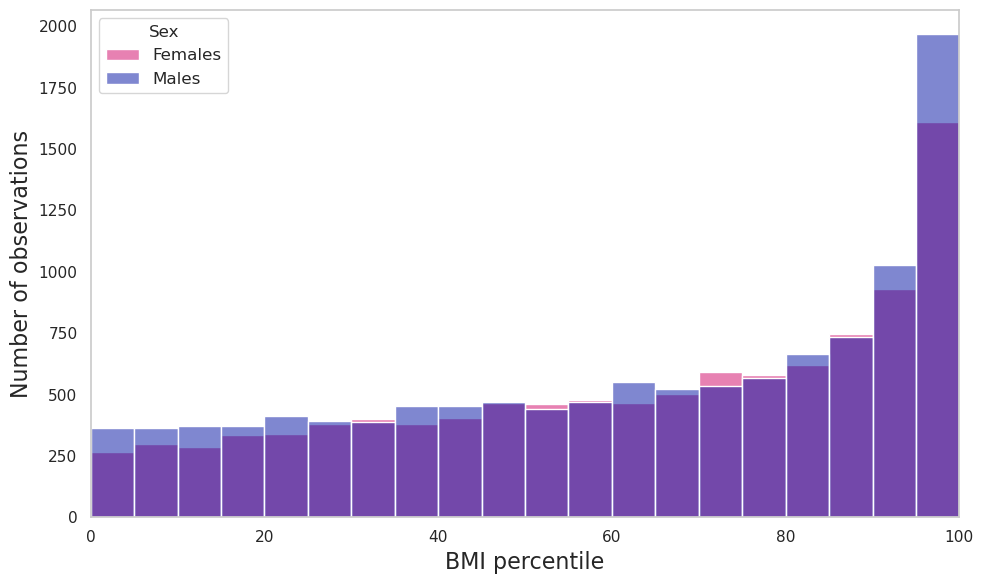

Saved /space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis/shared/sample_distribution_figures/perc_median_histogram_overlay.png


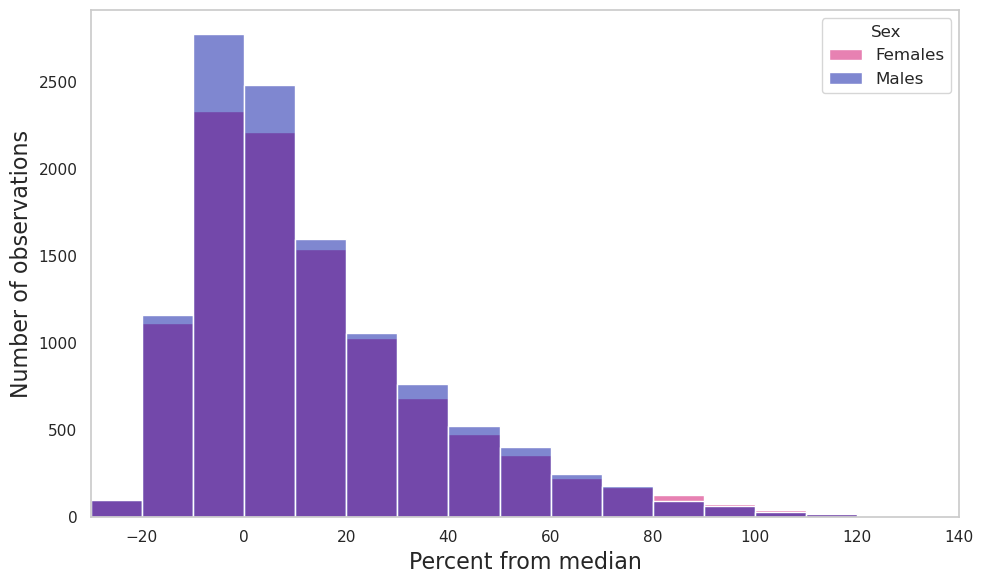

Saved /space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis/shared/sample_distribution_figures/anthro_bmi_histogram_overlay.png


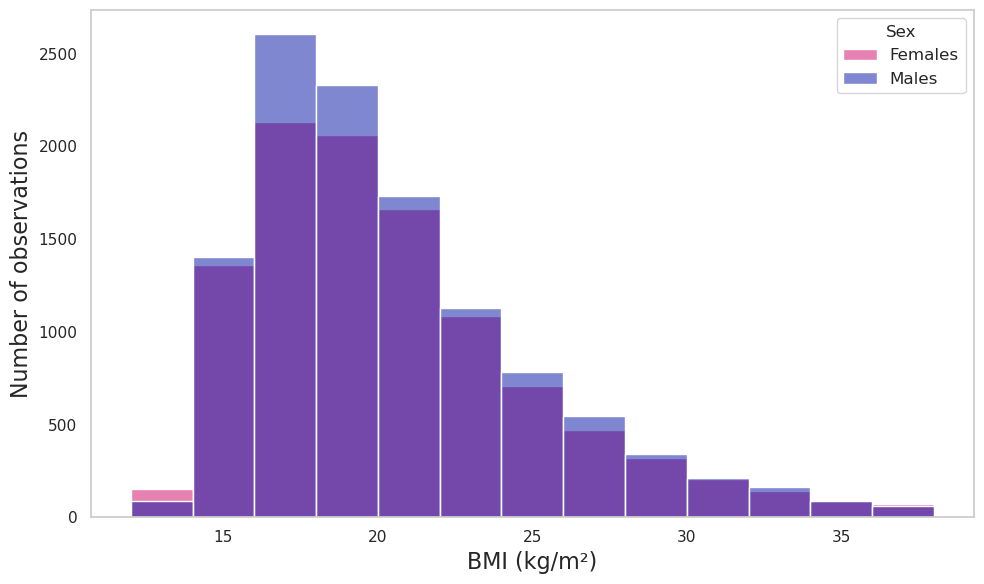

In [2]:
def plot_histogram_overlay(sub, spec):
    col = spec["column"]
    bins = make_bins(spec, sub[col].to_numpy())
    fig, ax = plt.subplots(figsize=(10, 6))
    hist_kw = dict(
        stat="count", bins=bins, kde=False, ax=ax, alpha=HIST_BAR_ALPHA,
    )
    if HIST_BAR_EDGE:
        hist_kw["edgecolor"] = HIST_BAR_EDGE_COLOR
        hist_kw["linewidth"] = HIST_BAR_EDGE_WIDTH
    for sex in ["F", "M"]:
        vals = sub.loc[sub[SEX_COL] == sex, col]
        sns.histplot(
            vals, color=SEX_PALETTE[sex], label=SEX_LABELS[sex], **hist_kw,
        )
    #ax.set_title(f"{spec['label']} — histogram by sex", fontsize=18)
    ax.set_xlabel(spec["label"], fontsize=16)
    ax.set_ylabel("Number of observations", fontsize=16)
    if spec["xlim"] is not None:
        ax.set_xlim(spec["xlim"])
    ax.grid(False)
    leg = ax.legend(title="Sex", fontsize=12)
    if HIST_LEGEND_SOLID:
        for handle in leg.legend_handles:
            handle.set_alpha(1.0)
    plt.tight_layout()
    save_fig(f"{spec['short']}_histogram_overlay")
    plt.show()


def plot_kde_quartiles(sub, spec):
    col = spec["column"]
    fig, ax = plt.subplots(figsize=(10, 6))
    for sex in ["F", "M"]:
        vals = sub.loc[sub[SEX_COL] == sex, col]
        sns.kdeplot(vals, color=SEX_PALETTE[sex], label=SEX_LABELS[sex], fill=True, alpha=0.25, ax=ax)
        q1, med, q3 = vals.quantile([0.25, 0.5, 0.75])
        for q, ls in [(q1, "--"), (med, "-"), (q3, "--")]:
            ax.axvline(q, color=SEX_PALETTE[sex], linestyle=ls, alpha=0.8)
    ax.set_title(f"{spec['label']} — density with quartiles", fontsize=18)
    ax.set_xlabel(spec["label"], fontsize=16)
    ax.set_ylabel("Density", fontsize=16)
    if spec["xlim"] is not None:
        ax.set_xlim(spec["xlim"])
    ax.legend(title="Sex", fontsize=10)
    plt.tight_layout()
    save_fig(f"{spec['short']}_kde_quartiles")
    plt.show()


for _key, spec in PHENO_SPECS.items():
    sub = pheno_series(df, spec)
    plot_histogram_overlay(sub, spec)
    #plot_kde_quartiles(sub, spec)


## eFigure 3–4 helpers. Age and PDS by sex (histogram overlays)


Saved /space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis/shared/sample_distribution_figures/age_histogram_overlay.png


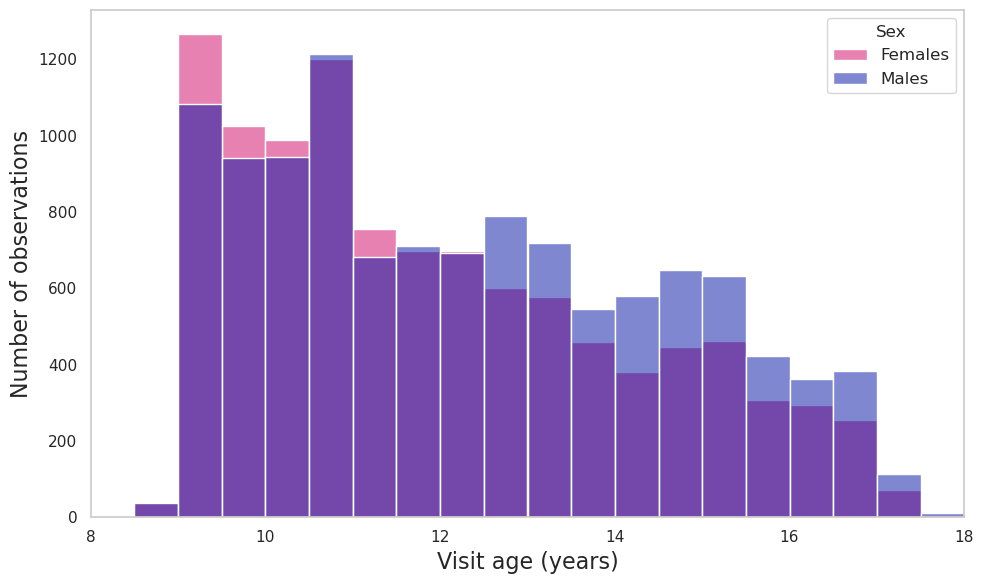

Saved /space/ceph/1/ABCD/users/arigby/2026_bmi_imaging_analysis/shared/sample_distribution_figures/pds_histogram_overlay.png


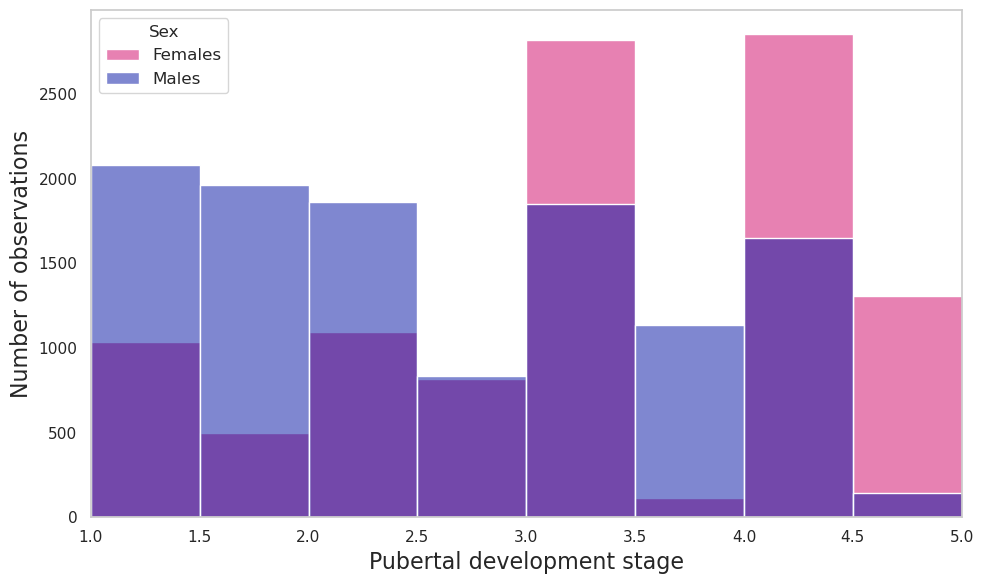

In [3]:
for _key, spec in COVAR_SPECS.items():
    sub = pheno_series(df, spec)
    plot_histogram_overlay(sub, spec)


## eFigure 2. Anthropometric measures by visit and sex


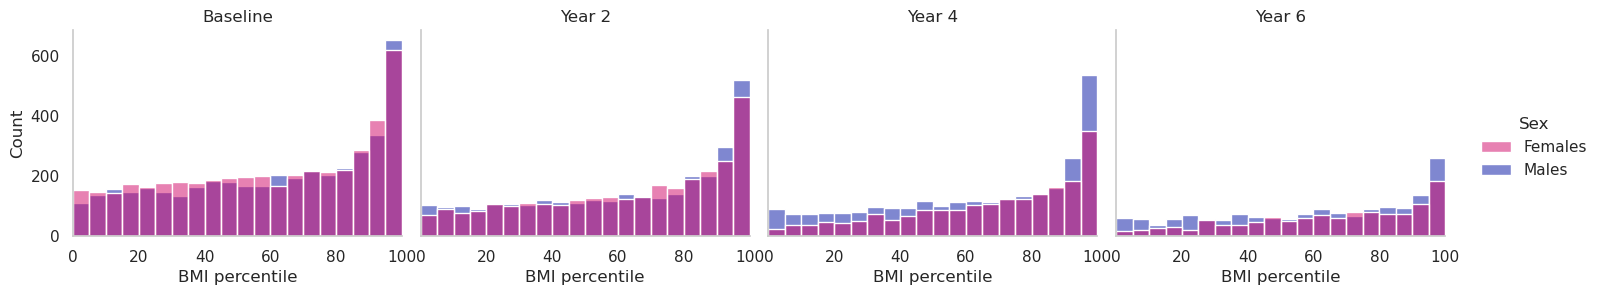

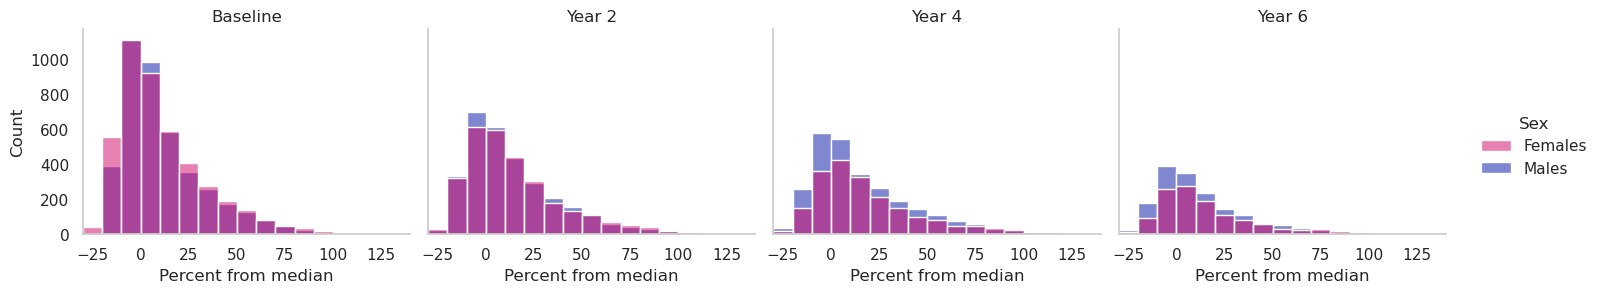

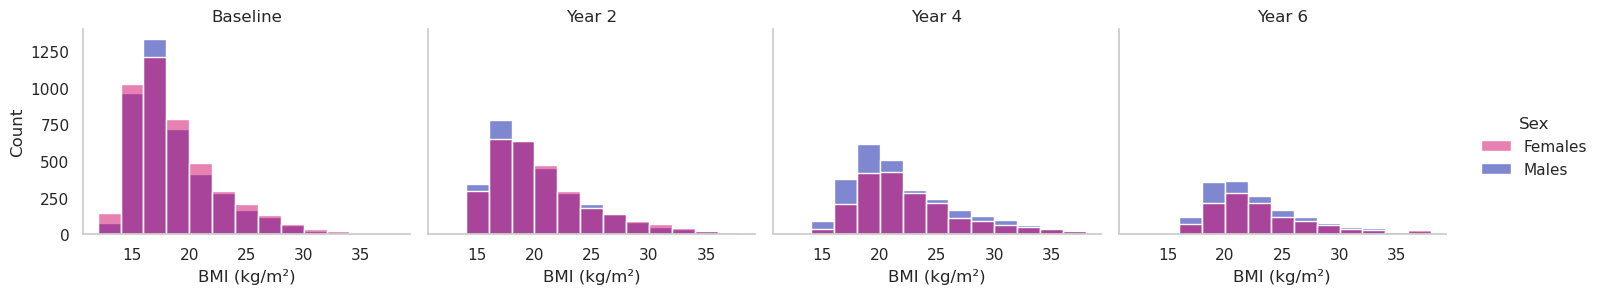

In [4]:
for _key, spec in PHENO_SPECS.items():
    col = spec["column"]
    plot_df = label_sex(label_sessions(pheno_series(df, spec)))
    plot_df = plot_df.dropna(subset=[col, "session_id", "sex_label"]).copy()
    bins = make_bins(spec, plot_df[col].to_numpy())
    session_order = session_label_order(plot_df)

    g = sns.displot(
        data=plot_df,
        x=col,
        col="session_label",
        col_order=session_order,
        col_wrap=4,
        hue="sex_label",
        hue_order=[SEX_LABELS["F"], SEX_LABELS["M"]],
        palette={SEX_LABELS["F"]: SEX_PALETTE["F"], SEX_LABELS["M"]: SEX_PALETTE["M"]},
        bins=bins,
        stat="count",
        common_bins=True,
        common_norm=False,
        multiple="layer",
        alpha=0.5,
        height=3.1,
        aspect=1.2,
    )
    g.set_axis_labels(spec["label"], "Count")
    g.set_titles("{col_name}")
    if spec["xlim"] is not None:
        g.set(xlim=spec["xlim"])
    for ax in g.axes.flat:
        ax.grid(False)
    g.fig.subplots_adjust(top=0.88)
    style_sex_legend(g._legend, title="Sex")
    save_fig(f"{spec['short']}_histogram_by_session")
    plt.show()


## Age and PDS by visit and sex (supports eFigures 2–4)


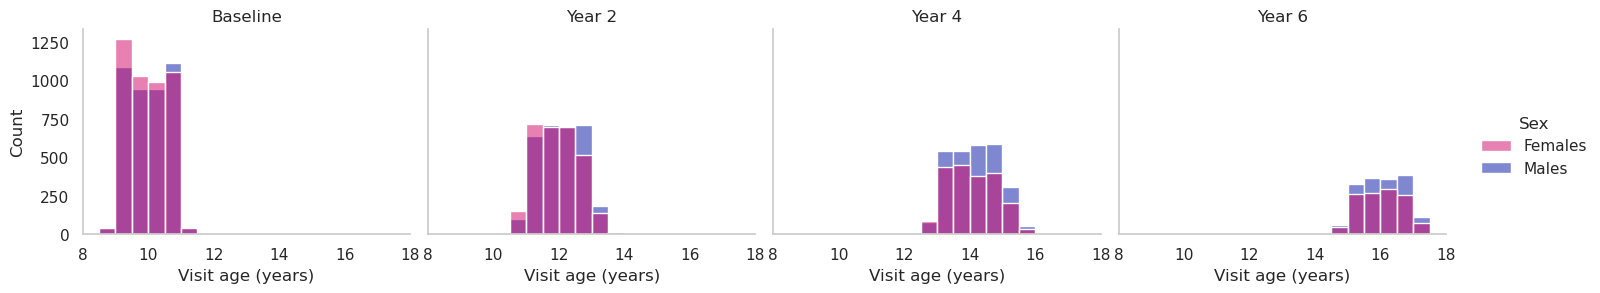

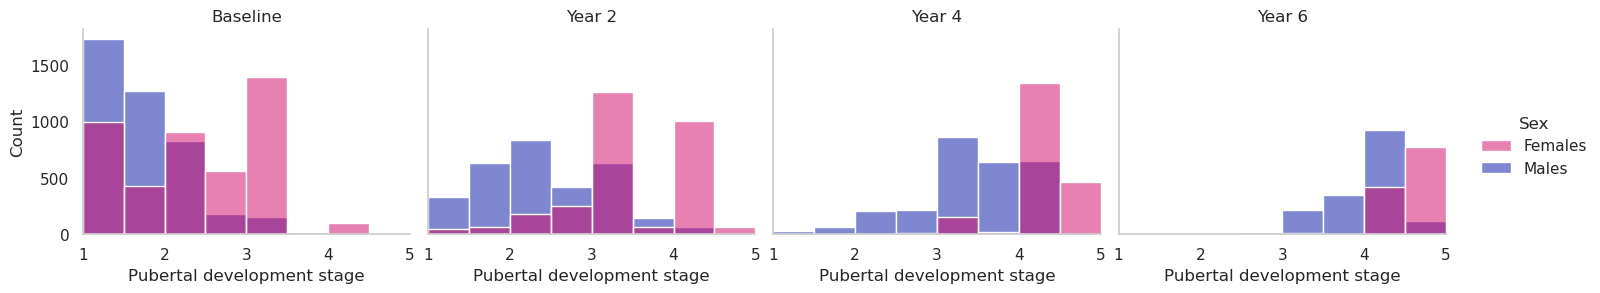

In [5]:
for _key, spec in COVAR_SPECS.items():
    col = spec["column"]
    plot_df = label_sex(label_sessions(pheno_series(df, spec)))
    plot_df = plot_df.dropna(subset=[col, "session_id", "sex_label"]).copy()
    bins = make_bins(spec, plot_df[col].to_numpy())
    session_order = session_label_order(plot_df)

    g = sns.displot(
        data=plot_df,
        x=col,
        col="session_label",
        col_order=session_order,
        col_wrap=4,
        hue="sex_label",
        hue_order=[SEX_LABELS["F"], SEX_LABELS["M"]],
        palette={SEX_LABELS["F"]: SEX_PALETTE["F"], SEX_LABELS["M"]: SEX_PALETTE["M"]},
        bins=bins,
        stat="count",
        common_bins=True,
        common_norm=False,
        multiple="layer",
        alpha=0.5,
        height=3.1,
        aspect=1.2,
    )
    g.set_axis_labels(spec["label"], "Count")
    g.set_titles("{col_name}")
    if spec["xlim"] is not None:
        g.set(xlim=spec["xlim"])
    for ax in g.axes.flat:
        ax.grid(False)
    g.fig.subplots_adjust(top=0.88)
    style_sex_legend(g._legend, title="Sex")
    save_fig(f"{spec['short']}_histogram_by_session")
    plt.show()
